# DuckDB Masterclass — Capítulo 14
## Integração Arrow, DuckDB-Wasm e MotherDuck

**Edição didática para estudo autônomo e publicação**  
**Contexto:** Operations Analytics e telecomunicações | **Dados:** sintéticos  
**Roteiro:** hipótese → executar → validar → interpretar → desafio → autoavaliação.

> Execute as células **de cima para baixo** em um kernel limpo. Resultados reais só devem ser salvos depois da execução no seu ambiente. Não publique dados privados, credenciais ou caminhos absolutos.

## 14.1 — Objetivos e diagnóstico

- Consultar DataFrame Pandas diretamente no DuckDB.
- Investigar Arrow opcional quando PyArrow estiver disponível.
- Distinguir execução local Python, navegador Wasm e serviço MotherDuck.
- Descrever cuidados de produção sem alegar deploy realizado.

**Pergunta de partida:** que risco operacional aparece quando utilizamos essa tecnologia de forma inadequada?

## 14.2 — Conceitos essenciais

DuckDB integra DataFrames locais, Arrow e SQL. DuckDB-Wasm executa no navegador; MotherDuck utiliza serviço externo. A troca de dados por Arrow pode reduzir conversões em cenários compatíveis, mas zero-copy não é garantia universal. Este notebook **não** implanta Wasm nem conecta ao MotherDuck.

### 🗺️ Modelo visual — Integração Arrow, DuckDB-Wasm e MotherDuck

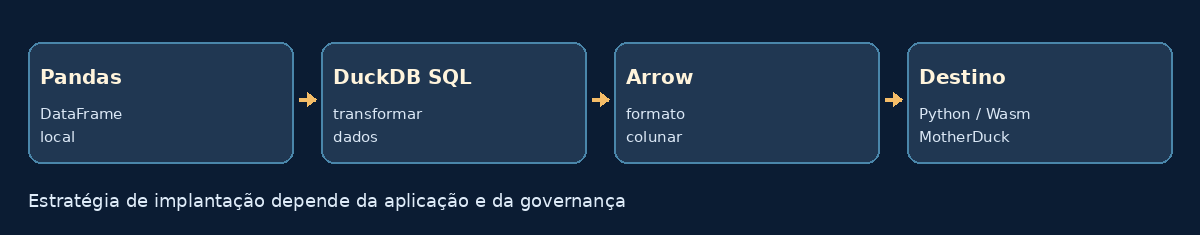

*Ilustração esquemática; não representa medição experimental.*

## 14.3 — Preparação e pré-requisitos

- Kernel recomendado: **Python (DuckDB Masterclass)**.
- Instale dependências ausentes no seu ambiente, fora do fluxo dos laboratórios.
- Cada arquivo produzido é sintético e deve ser salvo em pasta temporária ou `dados/` (ignorada pelo Git).
- Não execute instalação de extensões externas sem entender a necessidade, conectividade e eventuais custos.

## 14.4 — 🔬 Preparar integração com Pandas

**Hipótese / tarefa:** Registrar DataFrame sintético e agregar receita regional.

In [ ]:
import duckdb,pandas as pd
from IPython.display import display
con=duckdb.connect(':memory:')
vendas=pd.DataFrame({'regiao':['MS','MS','SP'],'receita':[100,150,200]})
con.register('vendas_pd',vendas)
print('Linhas registradas:',len(vendas))

**Interpretação e limite:** Registro temporário não equivale a tabela persistida.

## 14.5 — 🔬 Consultar a visão registrada

**Hipótese / tarefa:** Aplicar regra de negócio e validar o total.

In [ ]:
res=con.execute('SELECT regiao,SUM(receita) total FROM vendas_pd GROUP BY regiao ORDER BY regiao').df()
display(res)
assert int(res['total'].sum())==450

**Interpretação e limite:** DataFrame de origem permanece gerenciado por Python.

## 14.6 — 🔬 Exportar Arrow quando disponível

**Hipótese / tarefa:** Mostrar schema de Arrow ou instrução de instalação opcional.

In [ ]:
try:
 import pyarrow as pa
 tabela=con.execute('SELECT * FROM vendas_pd').arrow()
 print('Schema Arrow:',tabela.schema)
except ImportError:
 print('PyArrow não instalado; etapa Arrow opcional.')

**Interpretação e limite:** Disponibilidade de PyArrow depende do ambiente.

## 14.7 — 🔬 Checklist de decisão de produção

**Hipótese / tarefa:** Comparar opções sem credenciais, custos ou endpoints reais.

In [ ]:
alternativas={'Python':'Jupyter, scripts e jobs locais',
'Wasm':'Execução no navegador; políticas do browser e recursos disponíveis',
'MotherDuck':'Serviço externo; autenticação, custos e políticas de acesso'}
for destino,criterio in alternativas.items(): print(destino,':',criterio)
assert len(alternativas)==3

**Interpretação e limite:** Nenhuma implantação remota foi testada.

## 14.8 — 🎯 Desafio profissional

Uma análise de SLA deve rodar no computador do analista, no navegador do cliente ou em serviço compartilhado? Justifique por governança, volume, custo e privacidade.

**Critério de aceite:** apresentar a consulta ou procedimento, verificar uma hipótese e explicar pelo menos uma limitação. Resolva antes de consultar a referência abaixo.

### 🧠 Solução comentada / critérios de conferência

Avaliar a arquitetura por autenticação, compartilhamento, tamanho dos dados, operações concorrentes e custos. Não confundir API de interoperabilidade com migração automática.

## 14.9 — Autoavaliação

1. Explique o recurso sem reproduzir o código.
2. O que foi efetivamente demonstrado?
3. Que caso-limite poderia invalidar a interpretação?
4. Como validar a resposta com `assert`, SQL ou inspeção do plano?
5. Quando aplicaria isso em operações de telecomunicações?

**Gabarito orientador:** consulte a solução comentada do desafio e compare sua resposta com os resultados efetivamente observados; não conclua propriedades de performance ou produção sem evidência.

## 14.10 — Referências, reprodução e publicação

- [Arrow Integration](https://duckdb.org/docs/stable/guides/python/export_arrow.html)
- [Pandas Integration](https://duckdb.org/docs/stable/guides/python/import_pandas.html)
- [DuckDB-Wasm](https://duckdb.org/docs/stable/clients/wasm/overview.html)
- [MotherDuck](https://motherduck.com/docs/)

**Notas de engenharia:** Sem chave MotherDuck e sem configuração WebAssembly; laboratório de integração é local.

**Checklist editorial:** executar `Restart & Run All` quando aplicável; salvar saídas úteis; revisar integridade, privacidade, dependências e gráficos antes do `git add`.